In [91]:
import yfinance as yf
import pandas as pd
from datetime import datetime

In [92]:
# US 3-month treasury yield = 4.244% as of 12/11/2026

#### pulling the data

In [93]:
# retrieving spot price (S)

ticker = yf.Ticker("SPY")
spot = ticker.history(period="1d")['Close'].iloc[-1]
time_now = datetime.now().time()
spot

c:\Users\haris\Desktop\Coding Project\Black-Scholes Pricer workbook\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\haris\Desktop\Coding Project\Black-Scholes Pricer workbook\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\haris\Desktop\Coding Project\Black-Scholes Pricer workbook\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1

np.float64(760.4400024414062)

##### time to expiry data (T)

In [94]:
# retrieving time to expiry (T)

#Step 1: set the variable days_to_ex as the time to expiry for all listed SPY options on yahoo finance 
expiries = ticker.options  # selects all the expiration dates of the SPY options
today = (pd.Timestamp.today().normalize())  # 'today' represents today's date normalized (i.e. DD/MM/YY at midnight)

days_to_ex = {ex: (pd.Timestamp(ex) - today).days for ex in expiries}  # creates dictionary of the number of days to expiry for each expiration

#Step 2: choose 6 different expiry times ranging from a week to 6 months (approx.) to use in plotting the 3D iv surface
target_exs = [7, 30, 45, 60, 90, 120, 150, 180]  # 1week, 1month, 45days, 2months, 3months, 4months, 5months, 6months
chosen = set()

# for a given target t, scan all available options, find the one closest to the target ex date and add it to the set
for t in target_exs:
    closest_expiry = None
    min_diff = float('inf')  # start with infinitely large difference
    
    for e in expiries:
        days = days_to_ex[e]  # how many days to expiry is this specific option
        diff = abs(days - t)  # how far is it from the target

        if diff < min_diff:
            min_diff = diff
            closest_expiry = e

    chosen.add(closest_expiry)

chosen = sorted(list(chosen))

chosen


['2026-11-19',
 '2026-12-11',
 '2026-12-24',
 '2027-01-15',
 '2027-02-19',
 '2027-03-19',
 '2027-04-16',
 '2027-04-30']

##### creating option dataframe

In [96]:

d_frames = []  # initialises empty list to store Dataframes as they are processed in the loop

# loops through every option chain for each expiry and creates a dataframe for every option type
for e in chosen:
    chain = ticker.option_chain(e)
    for df, option_type in ((chain.calls, "call"), (chain.puts, "put")):
        df = df.copy()  # creating safe copy of the DataFrame to avoid modifying the original data
        df["option_type"] = option_type  # add call/put column
        df["expiry"] = e  # add expiry column
        df["spot"] = spot  # add spot price column
        df["snapshot"] = time_now  # add timestamp for when snapshot was recorded column 
        d_frames.append(df)

chains_df = pd.concat(d_frames, ignore_index=True)  # stacks all seperate dataframes into one, setting a new sequential index
chains_df

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,option_type,expiry,spot,snapshot
0,SPY261119C00690000,2026-11-09 15:23:07+00:00,690.0,60.72,71.76,74.57,0.0,0.0,1.0,10.0,0.518804,True,REGULAR,USD,call,2026-11-19,760.440002,16:41:24.096758
1,SPY261119C00695000,2026-11-06 14:47:08+00:00,695.0,48.64,66.78,69.20,0.0,0.0,8.0,6.0,0.538701,True,REGULAR,USD,call,2026-11-19,760.440002,16:41:24.096758
2,SPY261119C00700000,2026-11-09 14:52:09+00:00,700.0,49.78,61.36,64.35,0.0,0.0,4.0,9.0,0.514531,True,REGULAR,USD,call,2026-11-19,760.440002,16:41:24.096758
3,SPY261119C00705000,2026-11-06 14:47:09+00:00,705.0,39.55,56.24,59.53,0.0,0.0,12.0,8.0,0.490789,True,REGULAR,USD,call,2026-11-19,760.440002,16:41:24.096758
4,SPY261119C00710000,2026-11-09 15:17:13+00:00,710.0,41.50,51.31,55.12,0.0,0.0,33.0,55.0,0.481450,True,REGULAR,USD,call,2026-11-19,760.440002,16:41:24.096758
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1688,SPY270430P00805000,2026-11-11 15:50:19+00:00,805.0,52.73,47.24,49.36,0.0,0.0,2.0,0.0,0.091608,True,REGULAR,USD,put,2027-04-30,760.440002,16:41:24.096758
1689,SPY270430P00810000,2026-10-30 18:47:11+00:00,810.0,62.17,51.17,54.33,0.0,0.0,1.0,1.0,0.097467,True,REGULAR,USD,put,2027-04-30,760.440002,16:41:24.096758
1690,SPY270430P00820000,2026-11-11 17:14:58+00:00,820.0,62.20,58.43,61.97,0.0,0.0,2.0,4.0,0.088571,True,REGULAR,USD,put,2027-04-30,760.440002,16:41:24.096758
1691,SPY270430P00870000,2026-10-29 15:35:13+00:00,870.0,99.74,105.85,109.62,0.0,0.0,NaN,0.0,0.078134,True,REGULAR,USD,put,2027-04-30,760.440002,16:41:24.096758


In [97]:
# saving
chains_df.to_csv("c:/Users/haris/Desktop/Coding Project/Black-Scholes Pricer workbook/data/SPY_option_chain_12-11-26.csv", index=False)

##### initial checks

In [102]:
check = pd.read_csv('SPY_option_chain_12-11-26.csv')
print(check.shape)
print(check.groupby(["expiry", "option_type"]).size())
print((check["bid"] == 0).mean())
print(chains_df.value_counts("expiry").sort_index())

(1693, 18)
expiry      option_type
2026-11-19  call            29
            put             24
2026-12-11  call           133
            put            111
2026-12-24  call            66
            put             76
2027-01-15  call           234
            put            185
2027-02-19  call            88
            put             86
2027-03-19  call           198
            put            139
2027-04-16  call            35
            put             44
2027-04-30  call           128
            put            117
dtype: int64
0.07619610159480213
expiry
2026-11-19     53
2026-12-11    244
2026-12-24    142
2027-01-15    419
2027-02-19    174
2027-03-19    337
2027-04-16     79
2027-04-30    245
Name: count, dtype: int64


#### testing & cleaning

In [103]:
import numpy as np

In [142]:
df = pd.read_csv("SPY_option_chain_12-11-26.csv")  # loading options dataset
r = 0.04244  # risk-free rate 12/11/26

# creating columns for required variables / data sorting

df["mid"] = (df["bid"] + df["ask"]) / 2  # creating column for option mid-prices: C/P
df["moneyness"] = df["strike"] / df["spot"]  # column for moneyness axis on 3D surface (moneyness < 1: strike below spot, moneyness > 1: strike above spot)

# filtering out "bad data": options far from spot price have worse data (fewer trades so stale quotes, zero-bids, prices barely react to vol)
intervals = [0, 0.8, 0.95, 1.05, 1.2, 10]
labels=["<0.8", "0.8-0.95", "0.95-1.05", "1.05-1.2", ">1.2"]
df["zones"] = pd.cut(df["moneyness"], bins=intervals, labels=labels)  # column for moneyness-filtered options

# column for all OTM options (better quoted since mostly traded)
df["otm"] = ((df["option_type"] == 'call') & (df['spot'] < df['strike'])) | ((df['option_type'] == 'put') & (df['spot'] > df['strike']))   

# column for 'T' (years to expiry)
snapshot_date = pd.Timestamp('2026-11-12')
df['T'] = (pd.to_datetime(df['expiry']) - snapshot_date).dt.days / 365



#### finding 'bad' data

In [ ]:
# zero / missing bid/ask quote
df['bad_quote'] = df['bid'].isna() | df['ask'].isna() | (df['bid'] == 0) | (df['ask'] == 0)  # isna() detects missing value
df.groupby('zones', observed=True)['bad_quote'].mean()  # mean value of bad quotes for each zone 

zones
<0.8         0.102970
0.8-0.95     0.000000
0.95-1.05    0.000000
1.05-1.2     0.014423
>1.2         0.446429
Name: bad_quote, dtype: float64

In [ ]:
# crossed quotes - ask should be > bid
print((df['bid'] > df['ask']).sum())  # how many crossed quotes
print(df[df['bid'] > df['ask']])  # at which row

1
          contractSymbol              lastTradeDate  strike  lastPrice  \
1057  SPY270319C00380000  2026-09-08 14:40:25+00:00   380.0     393.14   

         bid  ask  change  percentChange  volume  openInterest  ...  \
1057  394.54  0.0     0.0            0.0     3.0           0.0  ...   

      option_type      expiry        spot         snapshot     mid moneyness  \
1057         call  2027-03-19  760.440002  16:41:24.096758  197.27  0.499711   

      zones    otm                      T  bad_quote  
1057   <0.8  False 0 days 08:17:05.753424       True  

[1 rows x 24 columns]


In [ ]:
# wide spreads - check as a proportion of mid-price to ascertain whether mid-price is suitable fair price or not
valid = df[df['mid'] > 0].copy()  # dataframe of mid-prices greater than zero for valid division
valid['spread_to_mid'] = (valid['ask'] - valid['bid']) / valid['mid']  # checking spread / mid-price
valid.groupby('zones', observed=True)['spread_to_mid'].median()  # viewing the median spread : mid-price ration for each zone

zones
<0.8         0.016163
0.8-0.95     0.019417
0.95-1.05    0.009276
1.05-1.2     0.038462
>1.2         0.666667
Name: spread_to_mid, dtype: float64

In [115]:
# duplicates
df.duplicated('contractSymbol').sum()

np.int64(0)

In [ ]:
# strike coverage - whether the surface will have enough points inside 0.8-1.2 interval for each expiry
print(df.groupby('expiry')['moneyness'].agg(['min', 'max', 'count']))  # calculates lowest, highest moneyness and number of contracts for each expiry
print(df[df['moneyness'].between(0.8, 1.2)].groupby(['expiry', 'option_type']).size())  # how many calls and puts there are for each expiry within the moneyness interval

                 min       max  count
expiry                               
2026-11-19  0.907369  1.091473     53
2026-12-11  0.657514  1.222976    244
2026-12-24  0.657514  1.163800    142
2027-01-15  0.065751  1.946242    419
2027-02-19  0.526011  1.249277    174
2027-03-19  0.328757  1.946242    337
2027-04-16  0.328757  1.249277     79
2027-04-30  0.696965  1.196676    245
expiry      option_type
2026-11-19  call            29
            put             24
2026-12-11  call           117
            put             89
2026-12-24  call            65
            put             63
2027-01-15  call            61
            put             58
2027-02-19  call            59
            put             45
2027-03-19  call            61
            put             60
2027-04-16  call            27
            put             31
2027-04-30  call           122
            put            109
dtype: int64


In [143]:
# check T is correct
df.groupby("expiry")["T"].first() * 365  # checking the day count mathces calendar days from snapshot to expiry

expiry
2026-11-19      7.0
2026-12-11     29.0
2026-12-24     42.0
2027-01-15     64.0
2027-02-19     99.0
2027-03-19    127.0
2027-04-16    155.0
2027-04-30    169.0
Name: T, dtype: float64

In [ ]:
# how many usable rows survive per expiry 
usable = df[df["otm"] & (df["bid"] > 0) & df["moneyness"].between(0.8, 1.2)]
usable.groupby("expiry").size()

expiry
2026-11-19     29
2026-12-11    121
2026-12-24     80
2027-01-15     61
2027-02-19     61
2027-03-19     61
2027-04-16     46
2027-04-30    122
dtype: int64

In [ ]:
# date format and timezone
snap = pd.Timestamp("2026-11-12 16:41:24", tz="UTC")
last_trade = pd.to_datetime(df["lastTradeDate"], utc=True)

print(df[["lastTradeDate", "snapshot"]].head())
print(last_trade.min(), last_trade.max(), snap)  
print("latest trade minus snapshot:", last_trade.max() - snap)  # checks no trades are 'in the future' as this would signal a timezone mismatch (should return negative)


               lastTradeDate         snapshot
0  2026-11-09 15:23:07+00:00  16:41:24.096758
1  2026-11-06 14:47:08+00:00  16:41:24.096758
2  2026-11-09 14:52:09+00:00  16:41:24.096758
3  2026-11-06 14:47:09+00:00  16:41:24.096758
4  2026-11-09 15:17:13+00:00  16:41:24.096758
2025-05-30 14:52:27+00:00 2026-11-12 16:26:10+00:00 2026-11-12 16:41:24+00:00
latest trade minus snapshot: -1 days +23:44:46


count    1693.000000
mean        0.312913
std         0.314872
min         0.000010
25%         0.140870
50%         0.211022
75%         0.390173
max         3.364504
Name: impliedVolatility, dtype: float64
98
Axes(0.125,0.11;0.775x0.77)


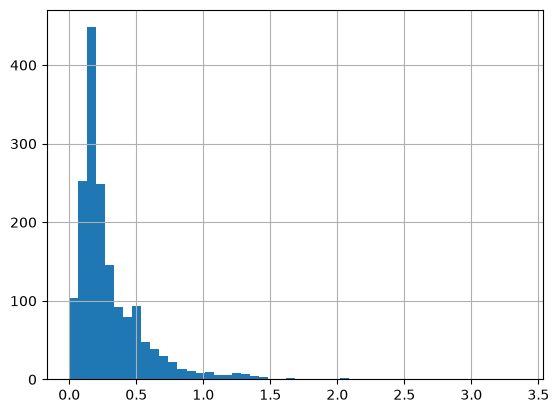

In [ ]:
# check Yahoo's implied vol - for reference post-plot
print(df["impliedVolatility"].describe())
print((df["impliedVolatility"] < 0.01).sum())
print(df["impliedVolatility"].hist(bins=50))

### plot

##### applying the solver